<a href="https://colab.research.google.com/github/jwalkorat/DeepLense-Test-Tasks-2026/blob/main/common_test_1/common_test_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepLense Common Test I: 3-class classification
ResNet18 (pretrained, 1-channel input) on no / sphere / vort. Ran on Google Colab (T4); dataset zip is on my Drive.
Full approach, results and limitations are in the README.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q "/content/drive/MyDrive/deeplense/dataset.zip" -d /content/
!ls /content

dataset  drive	__MACOSX  sample_data


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import models
from torchvision import transforms as T

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, auc, ConfusionMatrixDisplay, classification_report

from tqdm.notebook import tqdm
from pathlib import Path

In [4]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [6]:
train_dir = Path("/content/dataset/train")
val_dir = Path("/content/dataset/val")

In [7]:
def get_classes(directory):
    classes_ls = sorted([item.name for item in directory.iterdir() if not item.name.startswith(".")])
    classes_dict = {j: i for (i, j) in enumerate(classes_ls)}

    return classes_ls, classes_dict

get_classes(train_dir)

(['no', 'sphere', 'vort'], {'no': 0, 'sphere': 1, 'vort': 2})

In [8]:
class LensingDataset(Dataset):
    def __init__(self, train_dir, transform=None):
        self.train_dir = train_dir
        self.transform = transform

        self.images = list(self.train_dir.glob("*/*.npy"))
        self.classes_ls, self.classes_dict = get_classes(train_dir)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        img_path = self.images[index]
        img_class = self.classes_dict[img_path.parent.stem]

        # npy is (1,150,150), [0] drops the channel, ToTensor adds it back
        image = np.load(img_path)[0].astype(np.float32)

        if self.transform is not None:
            image = self.transform(image)

        return image, img_class

In [9]:
raw_data = LensingDataset(train_dir=train_dir,
                          transform=T.ToTensor())

# every 50th train image is enough for the stats
vals = torch.stack([raw_data[i][0] for i in range(0, len(raw_data), 50)])
custom_mean, custom_std = vals.mean().item(), vals.std().item()

custom_mean, custom_std

(0.061712801456451416, 0.11713721603155136)

In [10]:
train_transform = T.Compose([
    T.ToTensor(),
    T.Resize((256, 256)),  # resized for resnet
    T.Normalize(mean=[custom_mean],  # our own train mean/std, not ImageNet's
                std=[custom_std]),

    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=20)
])

val_transform = T.Compose([
    T.ToTensor(),
    T.Resize((256, 256)),
    T.Normalize(mean=[custom_mean],
                std=[custom_std])
])

In [11]:
train_dataset = LensingDataset(train_dir=train_dir, transform=train_transform)

val_dataset = LensingDataset(train_dir=val_dir, transform=val_transform)

In [12]:
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True
)

val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
    shuffle=False # no shuffle for val
)

In [13]:
# shape of dataloader batches

next(iter(train_dataloader))[0].shape

torch.Size([32, 1, 256, 256])

In [14]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 1-channel input, so conv1 is new and randomly initialised, rest is pretrained
model.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
model.fc = nn.Linear(in_features=512, out_features=3)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]


In [15]:
# quick shape check before training
rand_batch = torch.rand((32, 1, 150, 150)).to(device)

model.eval()
with torch.inference_mode():
  preds = model(rand_batch)

preds[:5], preds.shape

(tensor([[-0.0329,  0.3695, -0.5370],
         [-0.0806,  0.2307, -0.4941],
         [-0.0834,  0.3277, -0.5228],
         [-0.0213,  0.2079, -0.5661],
         [-0.0931,  0.3392, -0.4799]], device='cuda:0'),
 torch.Size([32, 3]))

In [16]:
def train_fn(model, dataloader, optimizer, loss_fn, scheduler, device=device):
    model.train()
    train_loss, train_acc = 0, 0

    with tqdm(dataloader, desc="Training", leave=False) as pbar:
        for batch, (X, y) in enumerate(pbar):
            X = X.to(device)
            y = y.to(device)

            preds = model(X)
            loss = loss_fn(preds, y)

            train_loss += loss.item()
            batch_acc = torch.eq(y, torch.argmax(preds, dim=1)).sum().item()
            train_acc += batch_acc

            pbar.set_postfix({
                "Batch": batch,
                "Loss": f"{loss.item():.4f}",
                "Batch Acc": f"{batch_acc * 100 / len(X):.2f}%"
            })

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            scheduler.step() # per batch, not per epoch

    train_loss /= len(dataloader)
    train_acc /= len(dataloader.dataset)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc * 100:.4f}%")

    return train_loss, train_acc


def evaluate(model, dataloader, loss_fn, device=device):
    model.eval()
    val_loss, val_acc = 0, 0

    with torch.inference_mode():
        with tqdm(dataloader, desc="Validation", leave=False) as pbar:
            for batch, (X, y) in enumerate(pbar):
                X = X.to(device)
                y = y.to(device)

                preds = model(X)
                loss = loss_fn(preds, y)

                val_loss += loss.item()
                batch_acc = torch.eq(y, torch.argmax(preds, dim=1)).sum().item()
                val_acc += batch_acc

                pbar.set_postfix({
                    "Batch": batch,
                    "Loss": f"{loss.item():.4f}",
                    "Batch Acc": f"{batch_acc * 100 / len(X):.2f}%"
                })

        val_loss /= len(dataloader)
        val_acc /= len(dataloader.dataset)

        print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc * 100:.4f}%\n")

    return val_loss, val_acc

In [17]:
train_loss_ls = []
train_acc_ls = []
test_loss_ls = []
test_acc_ls = []

In [18]:
epochs = 15

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-4, weight_decay=1e-4)

total_steps = len(train_dataloader) * epochs

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer=optimizer,
    T_max=total_steps, # T_max is in steps, not epochs, because the scheduler steps every batch
    eta_min=1e-6
)

In [19]:
for epoch in range(epochs):
    print(f"\n---- Epoch {epoch + 1}/{epochs} ----")

    train_loss, train_acc = train_fn(model, train_dataloader, optimizer, loss_fn, scheduler, device)

    val_loss, val_acc = evaluate(model, val_dataloader, loss_fn, device)

    train_loss_ls.append(train_loss)
    train_acc_ls.append(train_acc)
    test_loss_ls.append(val_loss)
    test_acc_ls.append(val_acc)



---- Epoch 1/15 ----


Training:   0%|          | 0/938 [00:00<?, ?it/s]

Train Loss: 0.8293 | Train Accuracy: 58.5000%


Validation:   0%|          | 0/235 [00:00<?, ?it/s]

Val Loss: 0.5210 | Val Accuracy: 77.6533%


---- Epoch 2/15 ----


Training:   0%|          | 0/938 [00:00<?, ?it/s]

... (51 outputs left out)

Training:   0%|          | 0/938 [00:00<?, ?it/s]

Train Loss: 0.0989 | Train Accuracy: 96.6267%


Validation:   0%|          | 0/235 [00:00<?, ?it/s]

Val Loss: 0.1041 | Val Accuracy: 96.4800%



In [20]:
torch.save(model.state_dict(), "resnet18_common_test1.pth")

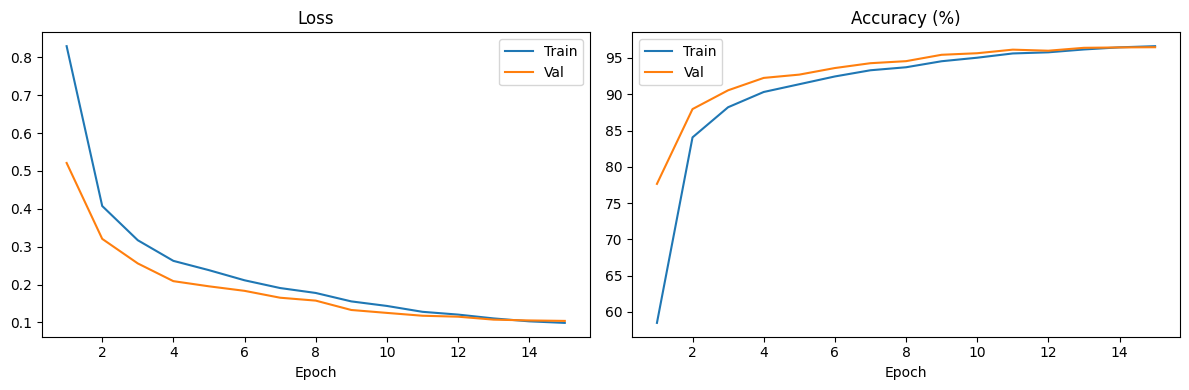

In [21]:
def plot_training_curves(train_loss, train_acc, val_loss, val_acc):
    epochs = range(1, len(train_loss) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label="Train")
    plt.plot(epochs, val_loss, label="Val")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.legend()

    # train acc is measured with augmentation on, so it can sit below val early on
    plt.subplot(1, 2, 2)
    plt.plot(epochs, [a * 100 for a in train_acc], label="Train")
    plt.plot(epochs, [a * 100 for a in val_acc], label="Val")
    plt.title("Accuracy (%)")
    plt.xlabel("Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_curves(train_loss_ls, train_acc_ls, test_loss_ls, test_acc_ls)

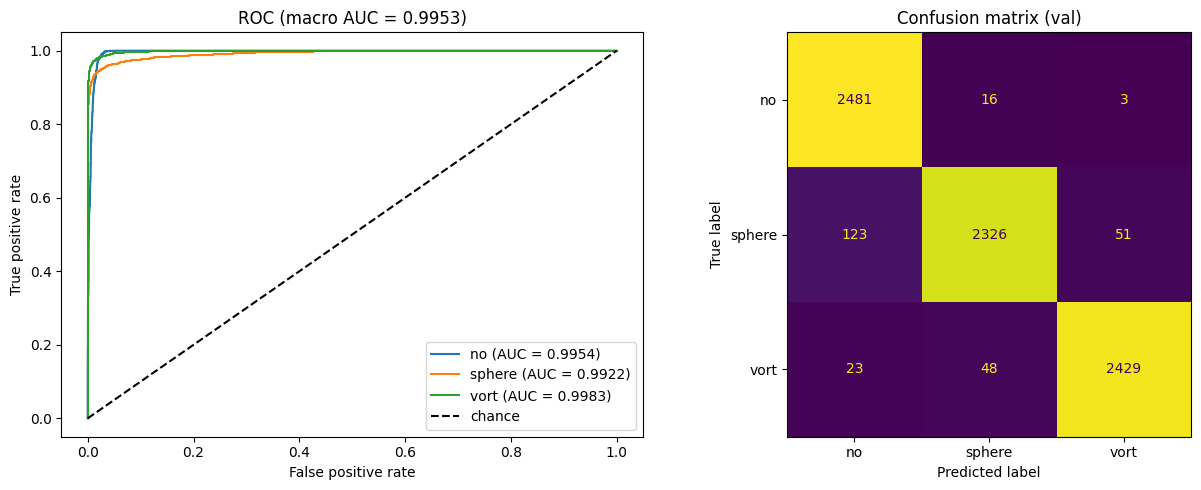

Accuracy: 96.48% | Macro AUC: 0.9953

              precision    recall  f1-score   support

          no       0.94      0.99      0.97      2500
      sphere       0.97      0.93      0.95      2500
        vort       0.98      0.97      0.97      2500

    accuracy                           0.96      7500
   macro avg       0.97      0.96      0.96      7500
weighted avg       0.97      0.96      0.96      7500



In [22]:
def evaluate_roc_confusion(model, dataloader, class_names, save_path="roc_confusion.png", device=device):

    # softmax probabilities for the whole val set
    model.eval()
    probs, labels = [], []

    with torch.inference_mode():
        for X, y in dataloader:
            probs.append(F.softmax(model(X.to(device)), dim=1).cpu())
            labels.append(y)

    probs = torch.cat(probs).numpy()
    labels = torch.cat(labels).numpy()
    preds = probs.argmax(1)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    # ROC is one-vs-rest: each class against the other two
    for i, name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(labels == i, probs[:, i])
        ax[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")

    macro_auc = roc_auc_score(labels, probs, multi_class="ovr", average="macro")
    ax[0].plot([0, 1], [0, 1], "k--", label="chance")
    ax[0].set(xlabel="False positive rate", ylabel="True positive rate",
              title=f"ROC (macro AUC = {macro_auc:.4f})")
    ax[0].legend(loc="lower right")

    ConfusionMatrixDisplay.from_predictions(
        labels, preds, display_labels=class_names, ax=ax[1], colorbar=False)
    ax[1].set_title("Confusion matrix (val)")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

    print(f"Accuracy: {(preds == labels).mean() * 100:.2f}% | Macro AUC: {macro_auc:.4f}\n")
    print(classification_report(labels, preds, target_names=class_names))

class_names = val_dataset.classes_ls   # ['no', 'sphere', 'vort']
evaluate_roc_confusion(model, val_dataloader, class_names)

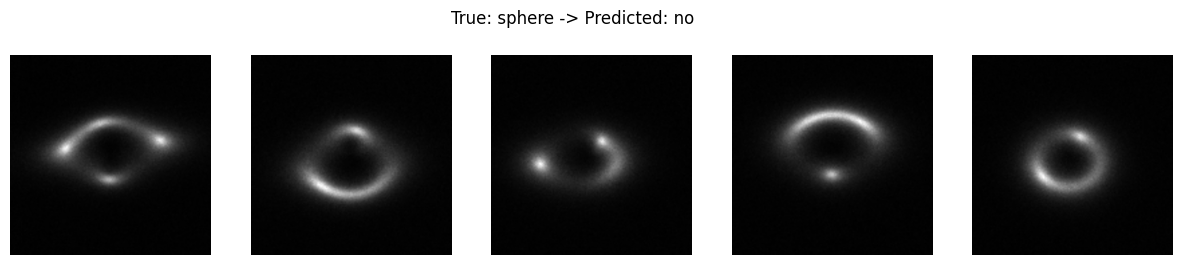

In [23]:
def plot_specific_errors(model, dataloader, class_names, true_class, pred_class, num_images=5, device=device):
    true_idx = class_names.index(true_class)
    pred_idx = class_names.index(pred_class)
    errors = []

    model.eval()
    with torch.inference_mode():
        for X, y in dataloader:
            preds = model(X.to(device)).argmax(1).cpu()
            errors += list(X[(y == true_idx) & (preds == pred_idx)])
            if len(errors) >= num_images:
                break

    # first ones found, not random. If fewer exist than asked, show all
    errors = errors[:num_images]
    if not errors:
        print(f"No '{true_class}' images predicted as '{pred_class}'")
        return

    fig, axes = plt.subplots(1, len(errors), figsize=(3 * len(errors), 3), squeeze=False)
    for ax, img in zip(axes[0], errors):
        ax.imshow(img[0], cmap="gray")
        ax.axis("off")
    fig.suptitle(f"True: {true_class} -> Predicted: {pred_class}")
    plt.show()

plot_specific_errors(model, val_dataloader, class_names, "sphere", "no", num_images=5)

In [25]:
check = models.resnet18(weights=None)
check.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
check.fc = nn.Linear(512, 3)

check.load_state_dict(torch.load("resnet18_common_test1.pth", map_location=device))
check.to(device)

evaluate(check, val_dataloader, loss_fn)   # should match the final val accuracy

Validation:   0%|          | 0/235 [00:00<?, ?it/s]

Val Loss: 0.1041 | Val Accuracy: 96.4800%



(0.10408957158760267, 0.9648)